# 10 — CatBoost ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

CatBoost (Yandex), kategorik değişkenleri ön işlemeye gerek kalmadan işleyebilen
ve **ordered boosting** tekniğiyle hedef sızıntısını ve aşırı öğrenmeyi azaltan bir
gradyan artırma kütüphanesidir. Simetrik (oblivious) ağaçlar kullanır ve varsayılan
ayarlarıyla dahi çoğu zaman iyi sonuç vermesiyle tanınır. Model varsayılan 1000 tur ve
**8** ağaç derinliğiyle (doğrulama kümesiyle seçildi) kurulmuştur.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
yc_tr_k = o.sinif_kodlari(yc_tr)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
reg_model = CatBoostRegressor(depth=8, random_state=42, verbose=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1408
   MSE: 0.0502
  RMSE: 0.2240
    R2: 0.7992
   AUC: 0.9835


In [3]:
o.reg_grafikleri(yr_te, y_pred, "CatBoost", "catboost")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\catboost_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = CatBoostClassifier(depth=8, random_state=42, verbose=0)
clf.fit(X_tr, yc_tr_k)
yp = o.koddan_sinifa(clf.predict(X_te))

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9415
   BalancedAcc: 0.9415
      F1_macro: 0.9415
   F1_weighted: 0.9415

              precision    recall  f1-score   support

  Yangın Yok      0.943     0.942     0.943       653
      Yangın      0.940     0.941     0.940       629

    accuracy                          0.941      1282
   macro avg      0.941     0.941     0.941      1282
weighted avg      0.942     0.941     0.941      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1408 |   0.4998 |    0.3931 | -0.2523 (iyi)
     MSE |   0.0502 |   0.2499 |    0.1978 | -0.1476 (iyi)
    RMSE |   0.2240 |   0.4999 |    0.4447 | -0.2207 (iyi)
      R2 |   0.7992 |  -0.0000 |    0.2086 | +0.5906 (iyi)
     AUC |   0.9835 |   0.5000 |    0.6982 | +0.2853 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9415 |   0.5094 |    0.6934 | +0.2480
     BalancedAcc |  0.9415 |   0.5000 |    0.6982 | +0.2433
        F1_macro |  0.9415 |   0.3375 |    0.6748 | +0.2667
     F1_weighted |  0.9415 |   0.3438 |    0.6733 | +0.2682
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "CatBoost", "catboost")

CatBoost — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   615     38
      Yangın |    37    592


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\catboost_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### Özellik Önemleri ve Ağaç Derinliğinin Etkisi

Simetrik ağaçta aynı seviyedeki bütün düğümler aynı soruyu sorar; derinlik, modelin
yakalayabileceği özellik etkileşimlerinin karmaşıklığını belirler. Aşırı derinlik
ezberlemeye yol açar. Önemler CatBoost'un varsayılan ölçütü olan tahmin değişimine
(PredictionValuesChange) göre verilmiştir.

In [7]:
o.ozellik_onem_grafigi(clf.feature_importances_, "CatBoost", "catboost")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\catboost_onem.png'

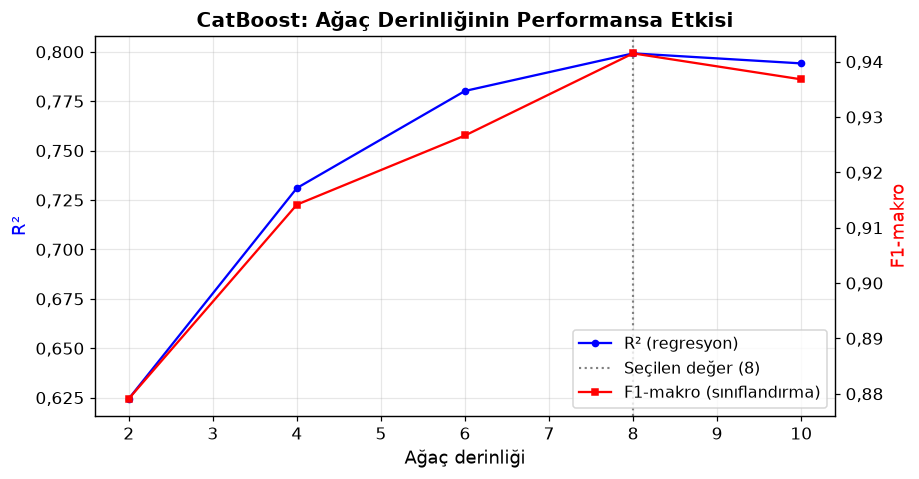

Tarama: [(2, 0.6244, 0.8791), (4, 0.731, 0.9142), (6, 0.7802, 0.9266), (8, 0.7992, 0.9415), (10, 0.7941, 0.9368)]
En yüksek R²: 0.7992 (8) · en yüksek F1-makro: 0.9415 (8)


In [8]:
degerler = [2, 4, 6, 8, 10]
r2_list, f1_list = [], []
for dd in degerler:
    r = CatBoostRegressor(depth=dd, random_state=42, verbose=0).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = CatBoostClassifier(depth=dd, random_state=42, verbose=0).fit(X_tr, yc_tr_k)
    f1_list.append(o.cls_metrikleri(yc_te, o.koddan_sinifa(c.predict(X_te)))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(8, color="gray", ls=":", lw=1.4, label="Seçilen değer (8)")
ax1.set_xlabel("Ağaç derinliği")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("CatBoost: Ağaç Derinliğinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "catboost_depth_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [9]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = CatBoostRegressor(depth=8, random_state=42, verbose=0).fit(Xa, yra).predict(Xb)
    c_tahmin = o.koddan_sinifa(CatBoostClassifier(depth=8, random_state=42, verbose=0).fit(Xa, o.sinif_kodlari(ysa)).predict(Xb))
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2909 · F1-makro 0.7728


  kat 2: eğitim  4170 · sınama   958 · R² +0.2198 · F1-makro 0.6690


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5746 · F1-makro 0.8591


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4775 · F1-makro 0.8434


  kat 5: eğitim  4150 · sınama   978 · R² +0.5619 · F1-makro 0.8822
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.4249 ± 0.1442
  F1-makro: 0.8053 ± 0.0773


In [10]:
o.sonuc_kaydet("catboost", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\catboost.json


{'algoritma': 'catboost',
 'regresyon': {'MAE': 0.1407974801432657,
  'MSE': 0.050192582164069174,
  'RMSE': 0.2240370107015115,
  'R2': 0.799159283413426,
  'AUC': 0.9834955214650737},
 'siniflandirma': {'Accuracy': 0.9414976599063962,
  'BalancedAcc': 0.9414917574993245,
  'F1_macro': 0.9414788237334867,
  'F1_weighted': 0.9414984788704358},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.29094921964509823,
    0.21976319719170478,
    0.5746416374847005,
    0.47746502486718767,
    0.5619295654248526],
   'F1_macro': [0.7727903884735083,
    0.6690465223399356,
    0.8590834178250845,
    0.8434473027813087,
    0.8822060676390837],
   'R2_ort': 0.42494972892270877,
   'R2_std': 0.1442127932575188,
   'F1_ort': 0.8053147398117841,
   'F1_std': 0.07731015445838742},
  'duyarlilik': {'degerler': [2.0, 4.0, 6.0, 8.0, 10.0],
   'R2': [0.6244428721183807,
    0.7310240806282102,
    0.7801538170206258,
    0.799159283413426,
    0.7940940778392117],
   'F1_macro': [0.8790945017234